In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv("C:/Users/anand/OneDrive/Desktop/Retail Sales/retail_sales_dataset.csv")

In [7]:
df.shape

(1205, 13)

In [8]:
df.head()

,Order_ID,Order_Date,Customer_ID,Category,Product,Region,City,Quantity,Unit_Price,Discount,Sales,Profit,Payment_Mode
0,ORD011036,01-01-2025,CUST0174,Clothing,Jeans,South,Chennai,1,50.64,0.00,50.64,17.26,UPI
1,ORD010409,01-01-2025,CUST0052,Electronics,Monitor,West,Mumbai,2,209.71,0.05,398.45,101.16,Credit Card
2,ORD010604,01-01-2025,CUST0222,Electronics,Keyboard,West,Ahmedabad,5,48.10,0.00,240.50,47.27,Credit Card
3,ORD010261,01-01-2025,CUST0020,Office Supplies,Pen Set,West,Mumbai,3,5.62,0.15,14.33,6.29,UPI
4,ORD011080,02-01-2025,CUST0024,Home & Kitchen,Storage Box,North,Chandigarh,2,20.95,0.00,41.90,12.61,Debit Card


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1205 entries, 0 to 1204
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Order_ID      1205 non-null   str    
 1   Order_Date    1205 non-null   str    
 2   Customer_ID   1205 non-null   str    
 3   Category      1205 non-null   str    
 4   Product       1205 non-null   str    
 5   Region        1205 non-null   str    
 6   City          1201 non-null   str    
 7   Quantity      1205 non-null   int64  
 8   Unit_Price    1205 non-null   float64
 9   Discount      1201 non-null   float64
 10  Sales         1205 non-null   float64
 11  Profit        1205 non-null   float64
 12  Payment_Mode  1205 non-null   str    
dtypes: float64(4), int64(1), str(8)
memory usage: 122.5 KB


Data Cleaning

In [10]:
# Duplicate rows check
print('Duplicates:', df.duplicated().sum())

Duplicates: 5


In [11]:
# missing values check
print(df.isnull().sum())

Order_ID        0
Order_Date      0
Customer_ID     0
Category        0
Product         0
Region          0
City            4
Quantity        0
Unit_Price      0
Discount        4
Sales           0
Profit          0
Payment_Mode    0
dtype: int64


In [12]:
# Exact duplicate rows remove
df.dropna(inplace=True)

In [13]:
df.shape

(1197, 13)

In [14]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Category', 'Product',
       'Region', 'City', 'Quantity', 'Unit_Price', 'Discount', 'Sales',
       'Profit', 'Payment_Mode'],
      dtype='str')

In [15]:
# Date ko datetime format mein convert 
df['Order_Date'] = pd.to_datetime(
    df['Order_Date'],
    format='%d-%m-%Y'
)

In [16]:
# missing values handle 
df['Discount'] = df['Discount'].fillna(0)
df['City'] = df['City'].fillna(0)

In [17]:
# calculate business KPIs
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_unit = df['Quantity'].sum()
total_order = df['Order_ID'].unique()

In [18]:
print("Total Sales:", round(total_sales, 2))
print("Total_profit:", round(total_profit,2))
print("Total_units Sold:", total_unit)
print("Total Orders:", total_order)

Total Sales: 143558.39
Total_profit: 40294.2
Total_units Sold: 2364
Total Orders: <StringArray>
['ORD011036', 'ORD010409', 'ORD010604', 'ORD010261', 'ORD011080', 'ORD011189',
 'ORD011075', 'ORD010632', 'ORD011187', 'ORD010134',
 ...
 'ORD010503', 'ORD010294', 'ORD010146', 'ORD010039', 'ORD010797', 'ORD011092',
 'ORD010029', 'ORD010824', 'ORD010945', 'ORD010347']
Length: 1192, dtype: str


In [19]:
profit_margin = total_profit / total_sales * 100
average_order_value = total_sales / total_profit

In [20]:
print("Profit Margin:", round(profit_margin, 2), "%")
print("Average Order Value:", round(average_order_value, 2))

Profit Margin: 28.07 %
Average Order Value: 3.56


Category_wise sales and profit

In [21]:

category_sales = (
    df.groupby('Category')
    .agg(
        total_sales=('Sales','sum'),
        total_profit=('Profit', 'sum'),
        Unit_Salod = ('Quantity','sum')
    )
    .sort_values('total_sales',ascending=False)
)

display(category_sales)

,total_sales,total_profit,Unit_Salod
Category,,,
Electronics,64526.09,16606.34,765
Clothing,34615.87,10338.05,559
Home & Kitchen,22840.03,7576.18,578
Office Supplies,21576.40,5773.63,462


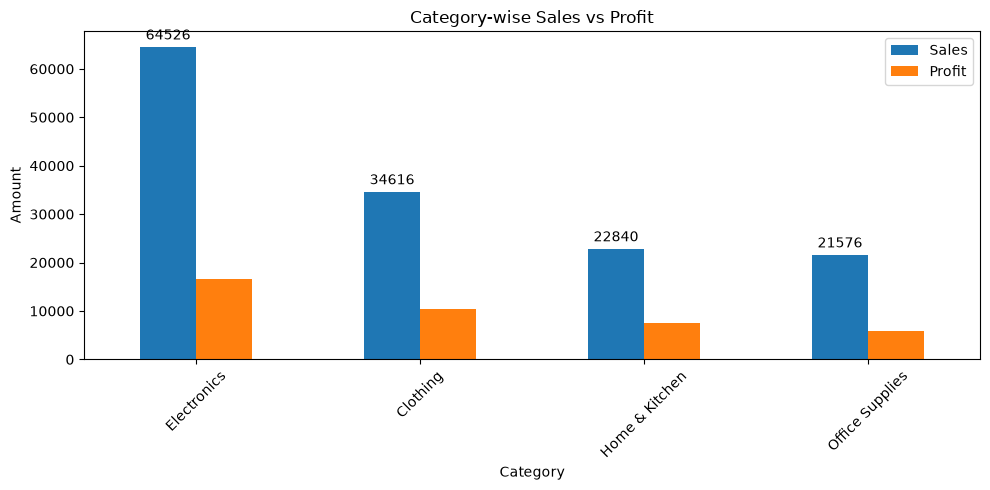

In [22]:


category_sales = (
    df.groupby('Category')
    .agg(
        total_sales=('Sales', 'sum'),
        total_profit=('Profit', 'sum'),
        Unit_Sold=('Quantity', 'sum')
    )
    .sort_values('total_sales', ascending=False)
)

# Bar chart

ax = category_sales[['total_sales', 'total_profit']].plot(
    kind='bar',
    figsize=(10, 5),
    title='Category-wise Sales vs Profit'
)
ax.bar_label(ax.containers[0], fmt='%.0f', padding=3)

plt.xlabel('Category')
plt.ylabel('Amount')
plt.xticks(rotation=45)
plt.legend(['Sales', 'Profit'])
plt.tight_layout()
plt.show()

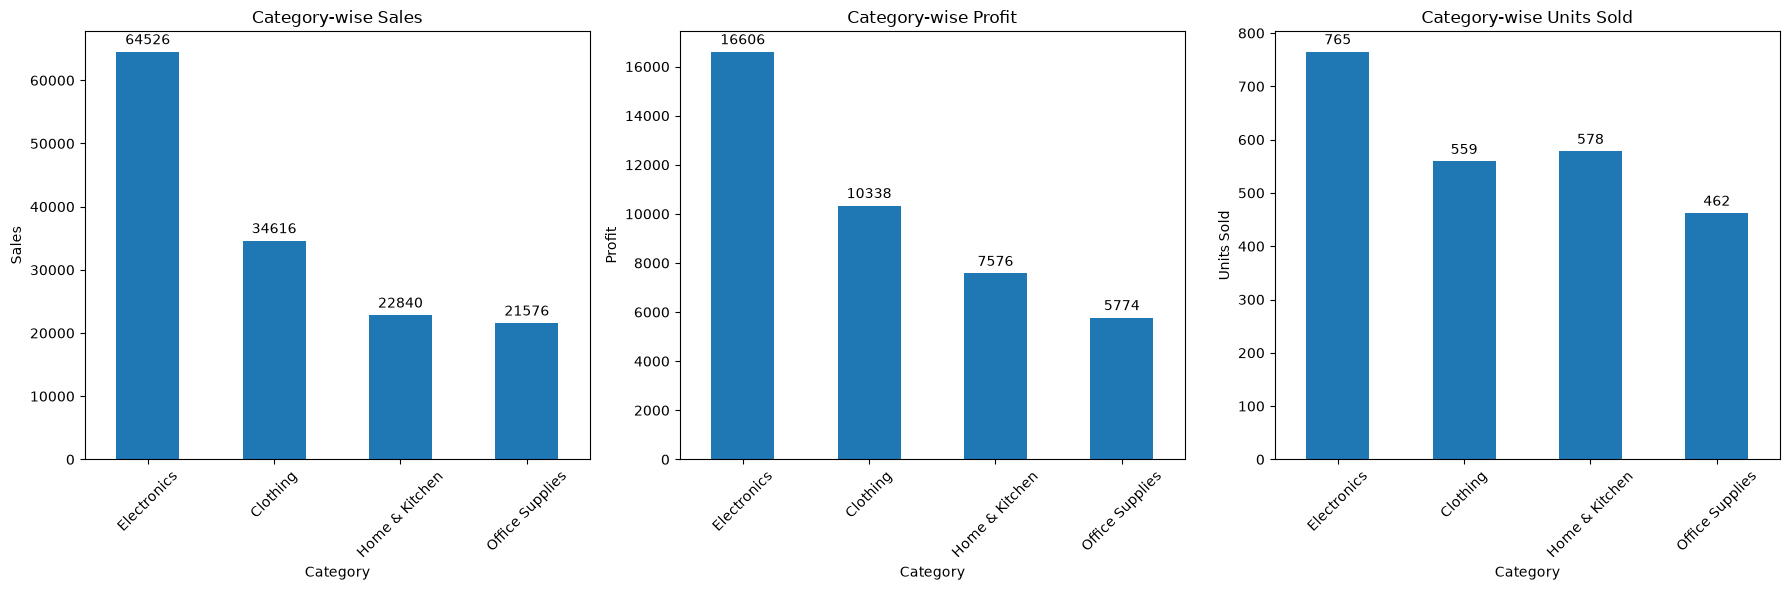

In [23]:

category_sales = (
    df.groupby('Category')
    .agg(
        total_sales=('Sales', 'sum'),
        total_profit=('Profit', 'sum'),
        Unit_Sold=('Quantity', 'sum')
    )
    .sort_values('total_sales', ascending=False)
)

# 3 alag bar charts
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Total Sales
category_sales['total_sales'].plot(
    kind='bar', ax=axes[0], title='Category-wise Sales'
)
axes[0].bar_label(axes[0].containers[0], fmt='%.0f', padding=3)
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Sales')
axes[0].tick_params(axis='x', rotation=45)

# 2. Total Profit
category_sales['total_profit'].plot(
    kind='bar', ax=axes[1], title='Category-wise Profit'
)
axes[1].bar_label(axes[1].containers[0], fmt='%.0f', padding=3)
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Profit')
axes[1].tick_params(axis='x', rotation=45)

# 3. Units Sold
category_sales['Unit_Sold'].plot(
    kind='bar', ax=axes[2], title='Category-wise Units Sold'
)
axes[2].bar_label(axes[2].containers[0], fmt='%.0f', padding=3)
axes[2].set_xlabel('Category')
axes[2].set_ylabel('Units Sold')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()



Monthly Sales Trend

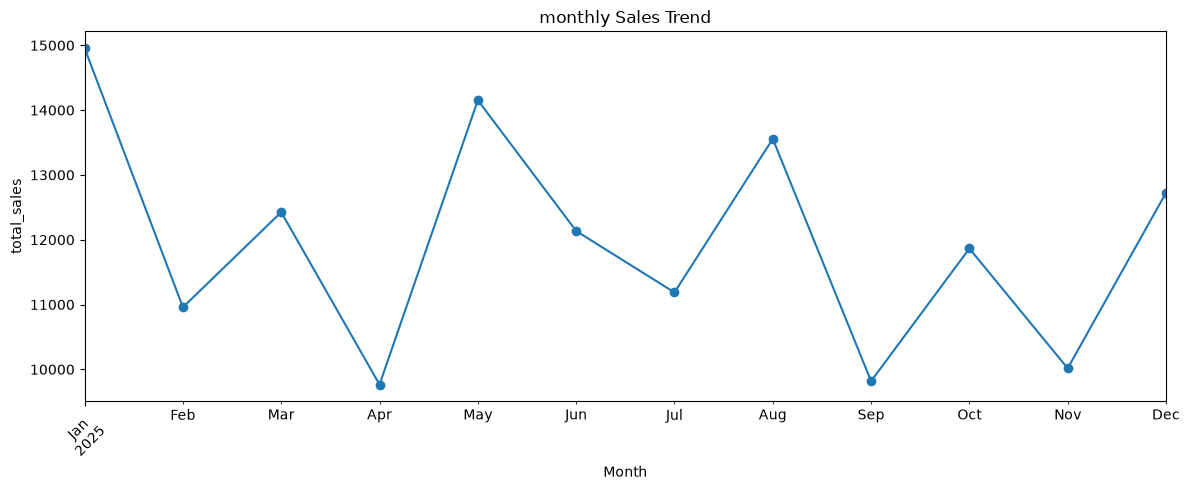

In [24]:
df['Month'] = df['Order_Date'].dt.to_period('M')

monthly_sales = df.groupby('Month')['Sales'].sum()

monthly_sales.plot( kind='line', marker='o', figsize=(12,5), title='monthly Sales Trend')

plt.xlabel('Month')
plt.ylabel('total_sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

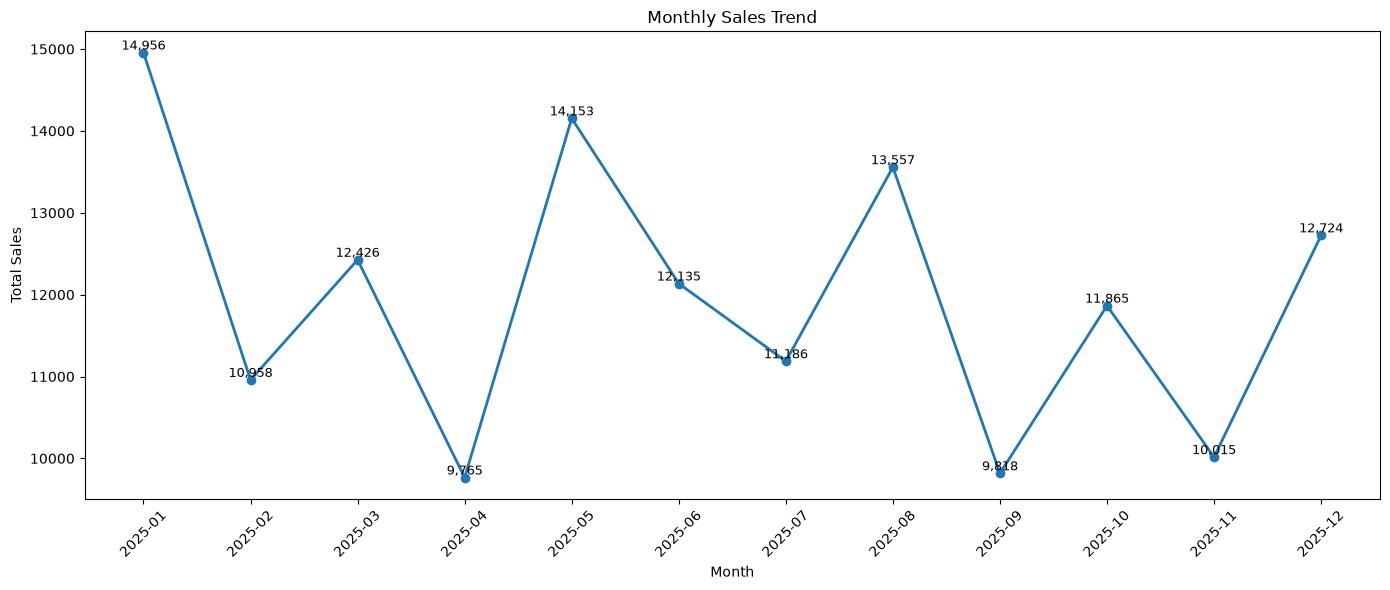

In [25]:

df['Month'] = df['Order_Date'].dt.to_period('M')
monthly_sales = df.groupby('Month')['Sales'].sum()

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    range(len(monthly_sales)),
    monthly_sales.values,
    marker='o',
    linewidth=2
)

# Har point ke upar number show karein
for i, value in enumerate(monthly_sales.values):
    ax.text(
        i, value,
        f'{value:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

ax.set_xticks(range(len(monthly_sales)))
ax.set_xticklabels(monthly_sales.index.astype(str), rotation=45)

ax.set_title('Monthly Sales Trend')
ax.set_xlabel('Month')
ax.set_ylabel('Total Sales')

plt.tight_layout()
plt.show()


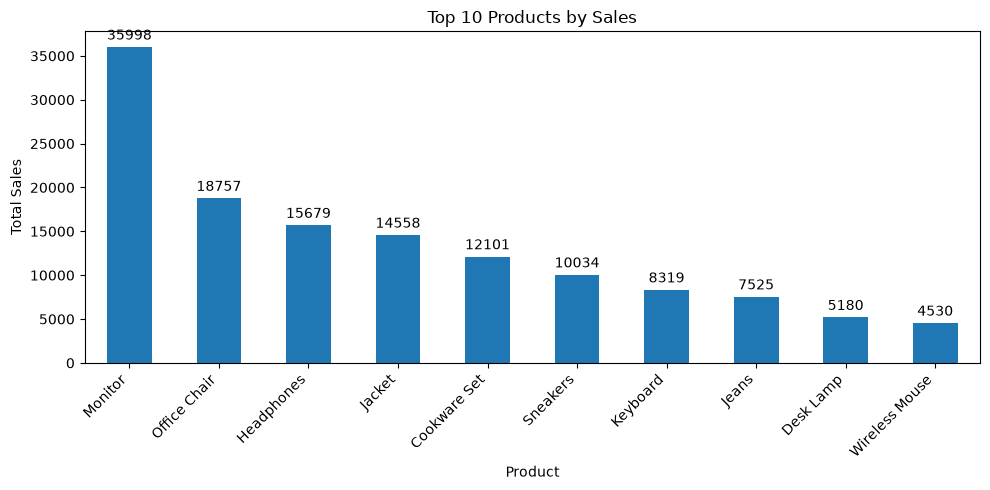

In [26]:
top_products = (
    df.groupby('Product')['Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

ax = top_products.plot(kind='bar', figsize=(10, 5))

# Bars ke upar numbers show karne ke liye
ax.bar_label(ax.containers[0], fmt='%.0f', padding=3)

plt.title('Top 10 Products by Sales')
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [27]:
city_products = df.groupby('City')['Product'].unique()

print(city_products)

City
Ahmedabad      [Keyboard, Desk Lamp, T-Shirt, Headphones, Mon...
Bengaluru      [Sneakers, Office Chair, Monitor, Pen Set, Des...
Bhubaneswar    [Office Chair, Water Bottle, Monitor, Storage ...
Chandigarh     [Storage Box, Jacket, Monitor, Wireless Mouse,...
Chennai        [Jeans, Monitor, Keyboard, Sneakers, Printer P...
Delhi          [Wireless Mouse, Cookware Set, T-Shirt, Monito...
Hyderabad      [Wireless Mouse, Pen Set, Storage Box, Office ...
Jaipur         [Storage Box, Jeans, Water Bottle, Desk Lamp, ...
Kolkata        [Jacket, Pen Set, Notebook Pack, Keyboard, Off...
Mumbai         [Monitor, Pen Set, Water Bottle, Headphones, P...
Patna          [Jacket, T-Shirt, Water Bottle, Monitor, Offic...
Pune           [Wireless Mouse, T-Shirt, Desk Lamp, Printer P...
Name: Product, dtype: object


In [28]:
city_product_sales = (
    df.groupby(['City', 'Product'])['Sales']
    .sum()
    .reset_index()
)

top_3_products = (
    city_product_sales
    .sort_values(['City', 'Sales'], ascending=[True, False])
    .groupby('City')
    .head(3)
)

print(top_3_products)

            City       Product    Sales
6      Ahmedabad       Monitor  3700.29
2      Ahmedabad    Headphones  1946.68
3      Ahmedabad        Jacket  1548.05
22     Bengaluru       Monitor  2564.67
19     Bengaluru        Jacket  2155.11
24     Bengaluru  Office Chair  1748.49
38   Bhubaneswar       Monitor  2294.55
34   Bhubaneswar    Headphones   763.11
32   Bhubaneswar  Cookware Set   513.88
54    Chandigarh       Monitor  4500.23
50    Chandigarh    Headphones  2371.17
59    Chandigarh      Sneakers  1554.45
70       Chennai       Monitor  4095.44
72       Chennai  Office Chair  2694.43
66       Chennai    Headphones  1586.83
86         Delhi       Monitor  3190.45
83         Delhi        Jacket  1661.40
80         Delhi  Cookware Set  1337.67
102    Hyderabad       Monitor  3564.09
104    Hyderabad  Office Chair  1367.86
96     Hyderabad  Cookware Set  1275.93
120       Jaipur  Office Chair  4247.46
118       Jaipur       Monitor  2564.62
114       Jaipur    Headphones  1653.94


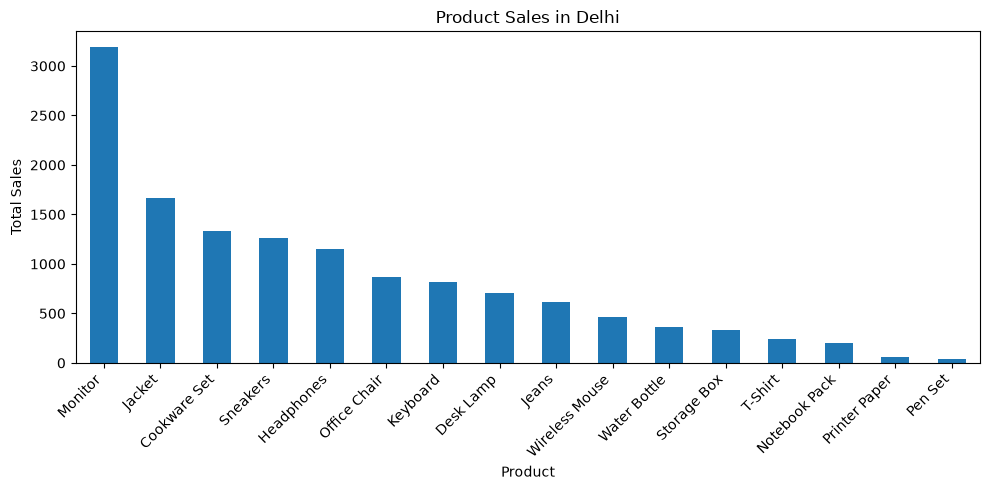

In [29]:


city = 'Delhi'  # Apni city ka naam yahan likho

city_data = (
    df[df['City'] == city]
    .groupby('Product')['Sales']
    .sum()
    .sort_values(ascending=False)
)

city_data.plot(kind='bar', figsize=(10, 5))

plt.title(f'Product Sales in {city}')
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

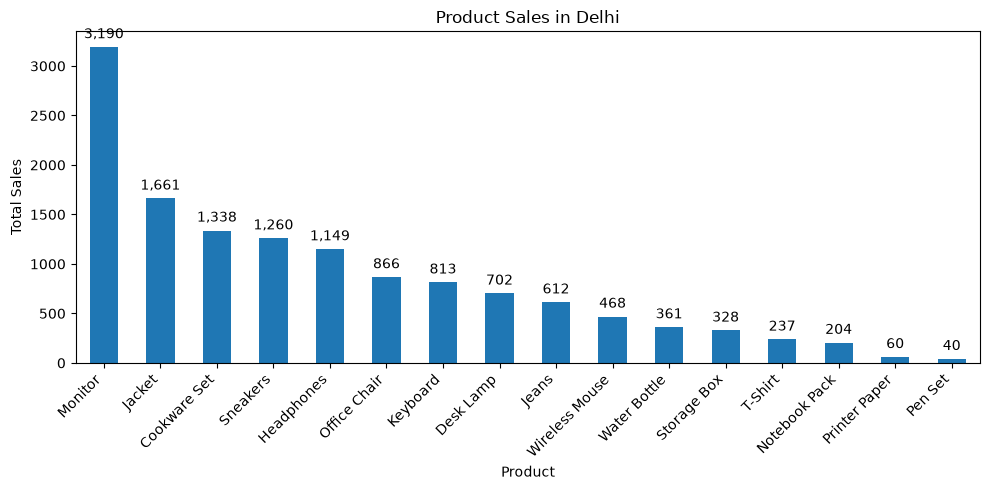

In [30]:

city = 'Delhi'

city_data = (
    df[df['City'] == city]
    .groupby('Product')['Sales']
    .sum()
    .sort_values(ascending=False)
)

ax = city_data.plot(
    kind='bar',
    figsize=(10, 5),
    title=f'Product Sales in {city}'
)

# Sabhi bars ke upar numbers
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='{:,.0f}',
        padding=4,
        fontsize=10
    )

plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
